# 04 · Evaluación y equidad

**Proyecto:** Alerta temprana de deserción · SENA
**Autor:** David · **Revisor:** Andrés

**Pregunta:** ¿el modelo detecta por igual a los desertores de cada grupo?

**Criterio acordado (6 nov):**

- **Principal: igualdad de oportunidades.** Todo aprendiz que va a desertar debe tener la misma probabilidad de recibir una alerta, sea del grupo que sea. Se mide con la **regla de los cuatro quintos** sobre el recall: `recall mínimo / recall máximo ≥ 0.80`, siempre con **intervalo de confianza por bootstrap**, porque los grupos son pequeños (presencial tiene 101 desertores en test).
- **Secundarias: precisión y tasa de alerta.** Con tasas de deserción de 22, 29 y 39 % no se pueden igualar a la vez que el recall: si un grupo deserta más, debe recibir más alertas.

**Por qué el recall:** es un sistema de apoyo, no de sanción. Lo más grave es que un desertor no reciba ayuda por pertenecer a un grupo; una falsa alarma cuesta una llamada del instructor.

**Grupos:**

- `modalidad`: atributo operativo; el modelo ya la usa.
- `sexo`: atributo **protegido** (Ley 1581 de 2012). Solo se usa aquí, desde `data/processed/auditoria.parquet`, para auditar. Nunca entra al modelo ni a los umbrales.

Las métricas por modalidad se **leen** de `reports/evaluacion.json` (etapa `evaluate`). La lógica de equidad vive en `src/desercion/equidad.py`; este cuaderno solo la usa y muestra los resultados.

## 1. Configuración

In [1]:
# Silencia avisos de librerías que no afectan el análisis (MLflow imprime rutas locales).
%env MLFLOW_DISABLE_AGENT_HINT=1
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

env: MLFLOW_DISABLE_AGENT_HINT=1


In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import GroupKFold, cross_val_predict

from desercion.equidad import (
    RATIO_MINIMO,
    alertar,
    bootstrap_recall,
    metricas_por_grupo,
    umbrales_por_grupo,
)
from desercion.modelado import (
    COLUMNA_GRUPO,
    RUTA_METRICAS,
    RUTA_MODELO,
    RUTA_TEST,
    RUTA_TRAIN,
    cargar_modelo,
    separar_x_y,
    tipos_de_columnas,
)
from desercion.train_model import cargar_config, construir_pipeline

# Raíz del repositorio: funciona tanto si el cuaderno se abre desde notebooks/ como desde la raíz.
RAIZ = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 4.5)
pd.set_option("display.precision", 3)

## 2. Datos, modelo y comprobación

Se usa **el modelo que versiona DVC** (`models/modelo.skops`, con `cargar_modelo`), no uno reentrenado aquí. El umbral se lee del JSON de `train`. La comprobación final asegura que este cuaderno ve exactamente lo mismo que la etapa `evaluate`; si falla, falta `uv run dvc pull` o `uv run dvc repro`.

In [3]:
test = pd.read_parquet(RAIZ / RUTA_TEST)
x_test, y_test = separar_x_y(test)
modelo = cargar_modelo(RAIZ / RUTA_MODELO)
UMBRAL = json.loads((RAIZ / RUTA_METRICAS).read_text(encoding="utf-8"))["umbral"]
evaluacion = json.loads(
    (RAIZ / "reports" / "evaluacion.json").read_text(encoding="utf-8")
)

probabilidad = modelo.predict_proba(x_test)[:, 1]
modalidad = x_test["modalidad"]
alerta = alertar(probabilidad, modalidad, UMBRAL)

# sexo solo desde la tabla de auditoría, unido por id_aprendiz.
auditoria = pd.read_parquet(RAIZ / "data" / "processed" / "auditoria.parquet")
sexo = test["id_aprendiz"].map(auditoria.set_index("id_aprendiz")["sexo"])
assert sexo.notna().all(), "Hay aprendices de test sin registro en auditoría"

# Comprobación: lo que calcula el cuaderno coincide con reports/evaluacion.json.
propio = metricas_por_grupo(y_test, alerta, modalidad)
for grupo, fila in evaluacion["modalidad"].items():
    for metrica in ["alertas", "verdaderos_positivos", "recall", "precision"]:
        assert np.isclose(propio.loc[grupo, metrica], fila[metrica]), (grupo, metrica)

print(
    f"Test: {len(test):,} aprendices · {int(y_test.sum())} desertores · umbral {UMBRAL:.3f}"
)
print("Coincide con reports/evaluacion.json ✓")

Test: 1,544 aprendices · 493 desertores · umbral 0.461
Coincide con reports/evaluacion.json ✓


## 3. Por modalidad

### 3.1 Lo que reporta la etapa `evaluate`

In [4]:
columnas = [
    "aprendices", "desertores", "tasa_desercion", "alertas", "tasa_alerta",
    "recall", "precision", "alertas_por_acierto", "mejora_sobre_azar",
]  # fmt: skip
por_modalidad = pd.DataFrame(
    {"global": evaluacion["global"], **evaluacion["modalidad"]}
).T[columnas]
por_modalidad

,aprendices,desertores,tasa_desercion,alertas,tasa_alerta,recall,precision,alertas_por_acierto,mejora_sobre_azar
global,1544.0,493.0,0.319,702.0,0.455,0.686,0.481,2.077,1.508
mixta,307.0,90.0,0.293,140.0,0.456,0.756,0.486,2.059,1.657
presencial,463.0,101.0,0.218,122.0,0.263,0.525,0.434,2.302,1.991
virtual,774.0,302.0,0.390,440.0,0.568,0.719,0.493,2.028,1.264


**Cuidado con `mejora_sobre_azar`.** Es igual a `recall / tasa_alerta`: compara al modelo con un sorteo **del mismo tamaño**. Sube cuando se alerta a **menos** personas. Presencial tiene la mayor (1.99×) porque se alerta solo al 26 % de sus aprendices, no porque el modelo funcione mejor ahí: de hecho, su precisión es la más baja. Sirve para saber si el modelo le gana al azar dentro de un grupo, **no para comparar grupos** con tasas de alerta distintas.

In [5]:
verificacion = por_modalidad["recall"] / por_modalidad["tasa_alerta"]
pd.DataFrame(
    {
        "mejora_sobre_azar": por_modalidad["mejora_sobre_azar"],
        "recall / tasa_alerta": verificacion,
    }
)

,mejora_sobre_azar,recall / tasa_alerta
global,1.508,1.508
mixta,1.657,1.657
presencial,1.991,1.991
virtual,1.264,1.264


### 3.2 Recall con intervalo de confianza y regla de los cuatro quintos

`prob_cumple` es la fracción de réplicas bootstrap en que el ratio es ≥ 0.80: cuánta seguridad hay en el veredicto.

In [6]:
ic_modalidad, ratio_modalidad = bootstrap_recall(y_test, alerta, modalidad)
display(ic_modalidad)
pd.Series(ratio_modalidad, name="modalidad · umbral global")

,recall,ic_inferior,ic_superior,desertores
grupo,,,,
mixta,0.756,0.663,0.839,90
presencial,0.525,0.426,0.619,101
virtual,0.719,0.667,0.767,302


ratio          0.695
ic_inferior    0.549
ic_superior    0.835
prob_cumple    0.069
Name: modalidad · umbral global, dtype: float64

### 3.3 ¿La brecha es sistemática o es ruido de la cohorte de prueba?

Si la brecha aparece también en train, con predicciones **out-of-fold** (cada aprendiz predicho por un modelo que no lo vio), no es casualidad de 2025-T3 y 2025-T4. Se usan los mismos folds que `train` (`GroupKFold` por cohorte).

In [7]:
train = pd.read_parquet(RAIZ / RUTA_TRAIN)
x_train, y_train = separar_x_y(train)
config = cargar_config(RAIZ / "config" / "model" / "logistic.yaml")
pipeline = construir_pipeline(*tipos_de_columnas(x_train), config)

probabilidad_oof = cross_val_predict(
    pipeline,
    x_train,
    y_train,
    groups=train[COLUMNA_GRUPO],
    cv=GroupKFold(n_splits=config["cv_n_splits"]),
    method="predict_proba",
)[:, 1]

recall_oof = metricas_por_grupo(
    y_train,
    alertar(probabilidad_oof, x_train["modalidad"], UMBRAL),
    x_train["modalidad"],
)["recall"]
pd.DataFrame(
    {"recall OOF (train)": recall_oof, "recall test": por_modalidad["recall"]}
).drop("global", errors="ignore")

,recall OOF (train),recall test
mixta,0.665,0.756
presencial,0.499,0.525
virtual,0.791,0.719


## 4. Por sexo (auditoría)

### 4.1 Global

In [8]:
columnas_sexo = [
    "aprendices",
    "desertores",
    "tasa_desercion",
    "tasa_alerta",
    "recall",
    "precision",
]
display(metricas_por_grupo(y_test, alerta, sexo)[columnas_sexo])

ic_sexo, ratio_sexo = bootstrap_recall(y_test, alerta, sexo)
display(ic_sexo)
pd.Series(ratio_sexo, name="sexo · umbral global")

,aprendices,desertores,tasa_desercion,tasa_alerta,recall,precision
grupo,,,,,,
F,866.0,267.0,0.308,0.441,0.674,0.471
M,678.0,226.0,0.333,0.472,0.699,0.494


,recall,ic_inferior,ic_superior,desertores
grupo,,,,
F,0.674,0.620,0.729,267
M,0.699,0.641,0.760,226


ratio          0.964
ic_inferior    0.852
ic_superior    0.998
prob_cumple    0.999
Name: sexo · umbral global, dtype: float64

### 4.2 Sexo dentro de cada modalidad

Los cruces dejan grupos de 43 a 164 desertores: las diferencias que se vean aquí pueden ser ruido. Por eso se muestran con su intervalo y no se usan para concluir por sí solas.

In [9]:
cruce = modalidad.astype(str) + " · " + sexo.astype(str)
ic_cruce, _ = bootstrap_recall(y_test, alerta, cruce)
ic_cruce

,recall,ic_inferior,ic_superior,desertores
grupo,,,,
mixta · F,0.660,0.512,0.790,47
mixta · M,0.860,0.755,0.951,43
presencial · F,0.536,0.404,0.667,56
presencial · M,0.511,0.361,0.654,45
virtual · F,0.726,0.655,0.794,164
virtual · M,0.710,0.631,0.782,138


## 5. Mitigación evaluada: un umbral por modalidad

Cada umbral se elige con las predicciones **out-of-fold de train** y el mismo criterio que el umbral global (recall ≥ 0.70 con la mayor precisión). Test solo se usa para evaluar.

In [10]:
umbrales = umbrales_por_grupo(
    y_train, probabilidad_oof, x_train["modalidad"], config["recall_objetivo"]
)
alerta_por_modalidad = alertar(probabilidad, modalidad, umbrales)
pd.Series(umbrales, name="umbral").to_frame().assign(umbral_global=UMBRAL)

,umbral,umbral_global
mixta,0.440,0.461
presencial,0.343,0.461
virtual,0.530,0.461


In [11]:
def comparar(metrica: str) -> pd.DataFrame:
    antes = metricas_por_grupo(y_test, alerta, modalidad)[metrica]
    despues = metricas_por_grupo(y_test, alerta_por_modalidad, modalidad)[metrica]
    return pd.DataFrame(
        {"umbral global": antes, "umbral por modalidad": despues}
    ).assign(cambio=lambda t: t["umbral por modalidad"] - t["umbral global"])


comparacion = pd.concat(
    {
        m: comparar(m)
        for m in [
            "verdaderos_positivos",
            "alertas",
            "recall",
            "precision",
            "alertas_por_acierto",
        ]
    },
    axis=1,
)
comparacion.loc["total"] = comparacion.sum(numeric_only=True).where(
    comparacion.columns.get_level_values(0).isin(["verdaderos_positivos", "alertas"])
)
comparacion

verdaderos_positivos                                   alertas  \
                  umbral global umbral por modalidad cambio umbral global   
grupo                                                                       
mixta                      68.0                 70.0    2.0         140.0   
presencial                 53.0                 69.0   16.0         122.0   
virtual                   217.0                194.0  -23.0         440.0   
total                     338.0                333.0   -5.0         702.0   

                                              recall                       \
           umbral por modalidad cambio umbral global umbral por modalidad   
grupo                                                                       
mixta                     148.0    8.0         0.756                0.778   
presencial                206.0   84.0         0.525                0.683   
virtual                   354.0  -86.0         0.719                0.642   
total                     708.0    6.0           NaN                  NaN   

                      precision                              \
           cambio umbral global umbral por modalidad cambio   
grupo                                                         
mixta       0.022         0.486                0.473 -0.013   
presencial  0.158         0.434                0.335 -0.099   
virtual    -0.076         0.493                0.548  0.055   
total         NaN           NaN                  NaN    NaN   

           alertas_por_acierto                              
                 umbral global umbral por modalidad cambio  
grupo                                                       
mixta                    2.059                2.114  0.055  
presencial               2.302                2.986  0.684  
virtual                  2.028                1.825 -0.203  
total                      NaN                  NaN    NaN

In [12]:
ic_mitigado, ratio_mitigado = bootstrap_recall(y_test, alerta_por_modalidad, modalidad)
_, ratio_sexo_mitigado = bootstrap_recall(y_test, alerta_por_modalidad, sexo)
pd.DataFrame(
    {
        "modalidad · umbral global": ratio_modalidad,
        "modalidad · umbral por modalidad": ratio_mitigado,
        "sexo · umbral global": ratio_sexo,
        "sexo · umbral por modalidad": ratio_sexo_mitigado,
    }
).T.assign(cumple=lambda t: t["ratio"] >= RATIO_MINIMO)

,ratio,ic_inferior,ic_superior,prob_cumple,cumple
modalidad · umbral global,0.695,0.549,0.835,0.069,False
modalidad · umbral por modalidad,0.826,0.714,0.931,0.608,True
sexo · umbral global,0.964,0.852,0.998,0.999,True
sexo · umbral por modalidad,0.938,0.827,0.997,0.993,True


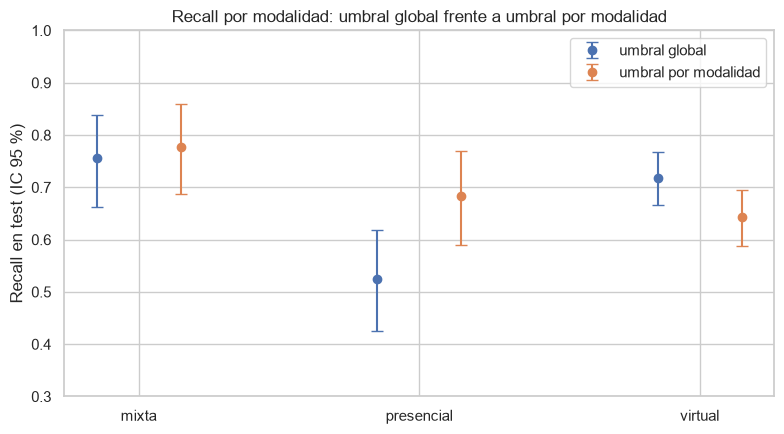

In [13]:
fig, ax = plt.subplots()
posiciones = np.arange(len(ic_modalidad))
for desplazamiento, (nombre, tabla) in zip(
    [-0.15, 0.15],
    [("umbral global", ic_modalidad), ("umbral por modalidad", ic_mitigado)],
):
    ax.errorbar(
        posiciones + desplazamiento,
        tabla["recall"],
        yerr=[
            tabla["recall"] - tabla["ic_inferior"],
            tabla["ic_superior"] - tabla["recall"],
        ],
        fmt="o",
        capsize=4,
        label=nombre,
    )
ax.set_xticks(posiciones, ic_modalidad.index)
ax.set_ylabel("Recall en test (IC 95 %)")
ax.set_ylim(0.3, 1)
ax.set_title("Recall por modalidad: umbral global frente a umbral por modalidad")
ax.legend()
plt.tight_layout()

## 6. Conclusiones

1. **Por modalidad, el umbral global no cumple la regla de los cuatro quintos.** El ratio es 0.69 (IC 95 %: 0.55–0.84) y solo el 7 % de las réplicas bootstrap llega a 0.80. Presencial tiene el recall más bajo (0.525; IC 0.43–0.62): de cada 100 aprendices presenciales que desertan, el modelo alerta a unos 52, frente a 72 en virtual y 76 en mixta.
2. **La brecha es sistemática.** Aparece también en train con predicciones out-of-fold (presencial 0.50, virtual 0.79), así que no es una casualidad de la cohorte de prueba. El coeficiente negativo de `modalidad_presencial` (cuaderno 02) hace que el modelo asigne probabilidades más bajas en presencial, donde además se deserta menos (22 %).
3. **La "mejora sobre el azar" de presencial (1.99×) no indica que el modelo funcione mejor ahí.** Es `recall / tasa_alerta` y crece al alertar a menos personas. No sirve para comparar grupos.
4. **Por sexo, el modelo cumple.** Ratio 0.96 (IC 0.85–1.00), con el 99.9 % de las réplicas sobre 0.80. Los cruces sexo × modalidad muestran diferencias (en mixta, 0.66 en mujeres frente a 0.86 en hombres), pero con 43 a 47 desertores por grupo sus intervalos son amplios y se solapan.
5. **Un umbral por modalidad reduce la brecha, pero redistribuye.** Con umbrales elegidos en train (mixta 0.44, presencial 0.34, virtual 0.53), el ratio sube a 0.83 (IC 0.71–0.93) con prácticamente las mismas alertas totales. A cambio: presencial gana 16 desertores detectados y virtual pierde 23; las alertas en presencial pasan de 122 a 206 y cada acierto cuesta 3 alertas en lugar de 2.3. Solo el 61 % de las réplicas cumple la regla: la mejora no es concluyente. La equidad por sexo se mantiene (0.94).

**Recomendación (ADR 0003):** mantener el umbral global en la v1 y documentar el umbral por modalidad como siguiente versión. Adoptarlo exige decidir quién asume el costo (más alertas en presencial y menos detección en virtual) y confirmarlo con más cohortes. Mientras tanto, la API debe reportar las alertas **por modalidad** para que la brecha sea visible.

## 7. Limitaciones

- **Datos sintéticos.** Las brechas describen el generador de datos, no al SENA real; el método es lo que se lleva a producción.
- **Grupos pequeños.** Con 90 a 302 desertores por modalidad en test, solo diferencias grandes son concluyentes; por eso todo se reporta con intervalo.
- **`sexo` binario.** La tabla de auditoría solo tiene F y M; no permite auditar otras identidades.
- **Una sola definición de equidad.** Se eligió igualdad de oportunidades; la paridad predictiva (precisión) y la de alertas no se cumplen a la vez y se reportan como secundarias.
- **Momento de la evaluación.** Todo corresponde a la semana 4; la equidad debe volver a medirse con cada cohorte nueva (`monitor.py`).